In [22]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Locate the project
project_dir = Path.home() / "Electives" / "South_african_weather_pipeline"

# Load the processed weather data
csv_path = project_dir / "data" / "processed" / "weather.csv"

df = pd.read_csv(csv_path)

# Display the first five records
display(df.head())

print("Total records:", len(df))
print("Unique cities:", df["city"].nunique())

,city,timestamp,temperature_c,humidity_percent,wind_speed_kmh
0,cape_town,2026-10-14T08:45,16.6,58,17.1
1,bloemfontein,2026-10-08T11:15,27.0,35,18.4
2,east_london,2026-10-14T10:30,28.6,71,16.6
3,pretoria,2026-10-08T11:15,27.4,33,8.9
4,east_london,2026-10-14T10:15,28.7,70,16.3


Total records: 79
Unique cities: 9


In [23]:
# Check the dataset's columns and data types
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 79 entries, 0 to 78
Data columns (total 5 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   city              79 non-null     str    
 1   timestamp         79 non-null     str    
 2   temperature_c     79 non-null     float64
 3   humidity_percent  79 non-null     int64  
 4   wind_speed_kmh    79 non-null     float64
dtypes: float64(2), int64(1), str(2)
memory usage: 3.2 KB


In [24]:
# Check for missing values in each column
print("Missing values:")
print(df.isnull().sum())

# Check for duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())

# Check for duplicate city and timestamp combinations
print(
    "Duplicate city-timestamp records:",
    df.duplicated(subset=["city", "timestamp"]).sum()
)

Missing values:
city                0
timestamp           0
temperature_c       0
humidity_percent    0
wind_speed_kmh      0
dtype: int64

Duplicate rows: 0
Duplicate city-timestamp records: 0


In [2]:
# Calculate average weather conditions for each city
city_summary = df.groupby("city").agg(
    average_temperature=("temperature_c", "mean"),
    average_humidity=("humidity_percent", "mean"),
    average_wind_speed=("wind_speed_kmh", "mean"),
    total_records=("timestamp", "count")
).reset_index()

# Round the averages to two decimal places
city_summary = city_summary.round(2)

# Display the results
display(city_summary)

NameError: name 'df' is not defined

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Find the project folder
project_dir = Path.home() / "Electives" / "South_african_weather_pipeline"

# Locate the processed weather CSV file
csv_path = project_dir / "data" / "processed" / "weather.csv"

# Load the weather data
df = pd.read_csv(csv_path)

# Display the first five rows
display(df.head())

# Show the total number of records
print("Total records:", len(df))
print("Unique cities:", df["city"].nunique())

,city,timestamp,temperature_c,humidity_percent,wind_speed_kmh
0,cape_town,2026-10-14T08:45,16.6,58,17.1
1,east_london,2026-10-20T08:00,20.8,36,8.3
2,bloemfontein,2026-10-08T11:15,27.0,35,18.4
3,east_london,2026-10-14T10:30,28.6,71,16.6
4,pretoria,2026-10-08T11:15,27.4,33,8.9


Total records: 87
Unique cities: 9


In [4]:
# Calculate average weather conditions for each city
city_summary = df.groupby("city").agg(
    average_temperature=("temperature_c", "mean"),
    average_humidity=("humidity_percent", "mean"),
    average_wind_speed=("wind_speed_kmh", "mean"),
    total_records=("timestamp", "count")
).reset_index()

# Round averages to two decimal places
city_summary = city_summary.round(2)

# Display the results
display(city_summary)

,city,average_temperature,average_humidity,average_wind_speed,total_records
0,bloemfontein,21.74,50.90,12.31,10
1,cape_town,16.98,57.62,17.29,8
2,durban,26.12,61.00,15.07,10
3,east_london,26.80,64.44,12.40,9
4,gqeberha,22.65,70.60,13.03,10
5,johannesburg,23.77,35.50,11.57,10
6,mbombela,26.11,58.20,9.65,10
7,polokwane,25.39,42.30,17.34,10
8,pretoria,27.03,28.90,10.84,10


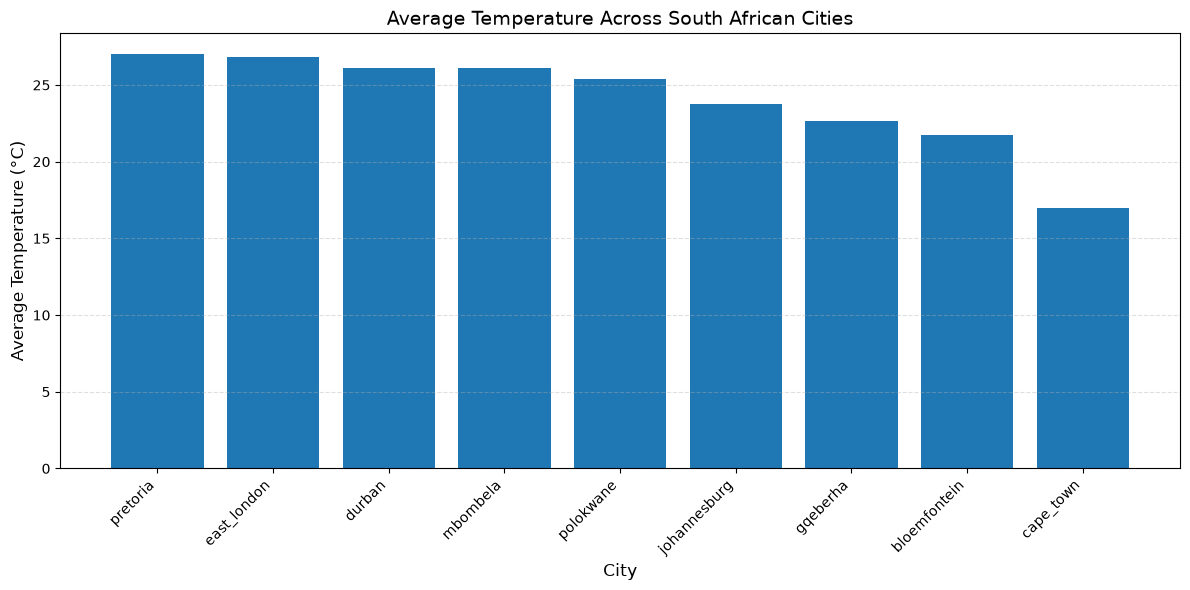

In [5]:
# Compare average temperatures across cities
temperature_summary = city_summary.sort_values(
    by="average_temperature",
    ascending=False
)

# Create the chart
plt.figure(figsize=(12, 6))

plt.bar(
    temperature_summary["city"],
    temperature_summary["average_temperature"]
)

# Add a title and labels
plt.title("Average Temperature Across South African Cities", fontsize=14)
plt.xlabel("City", fontsize=12)
plt.ylabel("Average Temperature (°C)", fontsize=12)

# Improve readability
plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()

# Display the chart
plt.show()

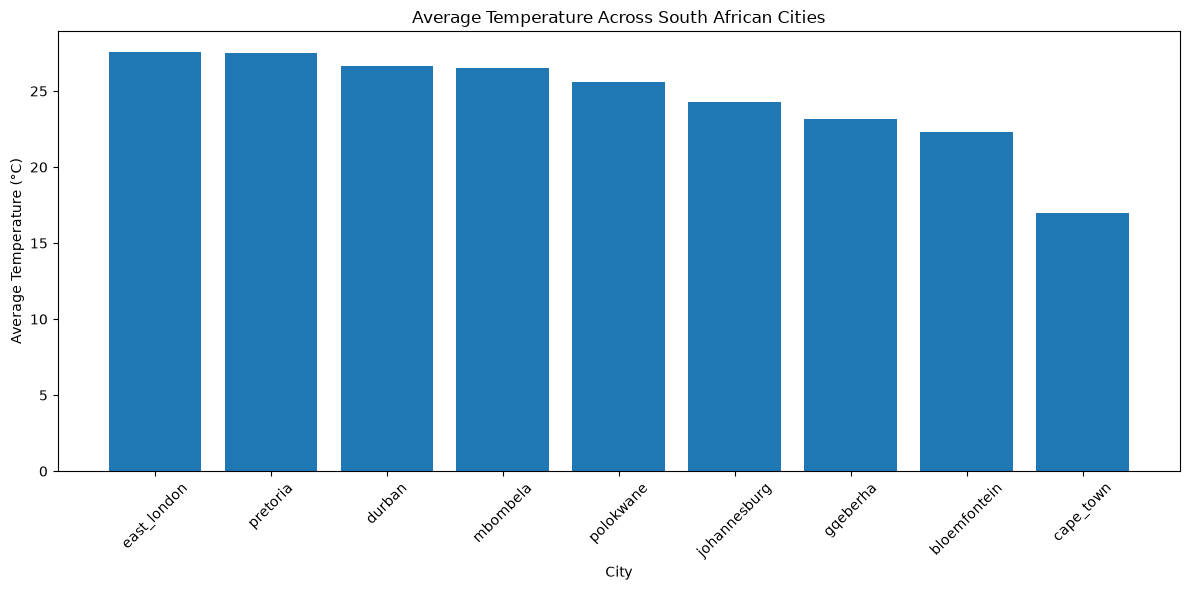

In [26]:
# Sort cities from warmest to coolest
temperature_summary = city_summary.sort_values(
    by="average_temperature",
    ascending=False
)

# Create the bar chart
plt.figure(figsize=(12, 6))

plt.bar(
    temperature_summary["city"],
    temperature_summary["average_temperature"]
)

plt.title("Average Temperature Across South African Cities")
plt.xlabel("City")
plt.ylabel("Average Temperature (°C)")
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

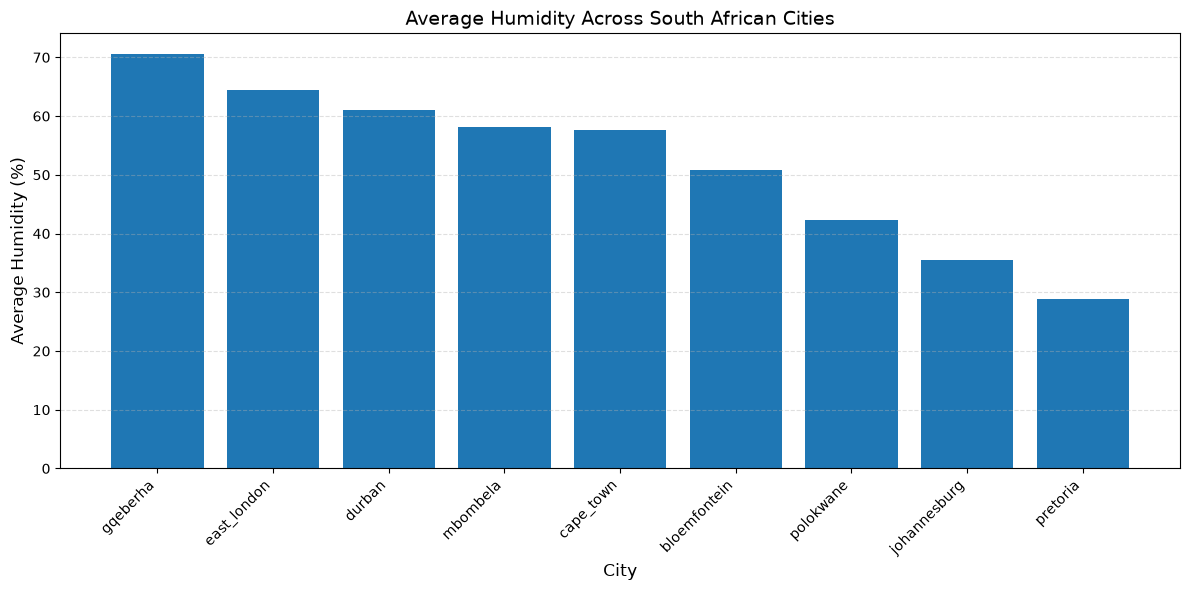

In [7]:
# Compare average humidity across cities
humidity_summary = city_summary.sort_values(
    by="average_humidity",
    ascending=False
)

# Create the chart
plt.figure(figsize=(12, 6))

plt.bar(
    humidity_summary["city"],
    humidity_summary["average_humidity"]
)

# Add a title and labels
plt.title("Average Humidity Across South African Cities", fontsize=14)
plt.xlabel("City", fontsize=12)
plt.ylabel("Average Humidity (%)", fontsize=12)

# Improve readability
plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()

# Display the chart
plt.show()

### Temperature Analysis

The collected weather readings show differences in average
temperature across the nine South African cities.

East London recorded the highest average temperature at 27.55°C,
while Cape Town recorded the lowest at 16.98°C.

This comparison provides an overview of the temperatures recorded
by the pipeline during the collection period. The averages should
not be interpreted as long-term climate averages.

# Sort cities from highest to lowest average humidity
humidity_summary = city_summary.sort_values(
    by="average_humidity",
    ascending=False
)

# Create the bar chart
plt.figure(figsize=(12, 6))

plt.bar(
    humidity_summary["city"],
    humidity_summary["average_humidity"]
)

plt.title("Average Humidity Across South African Cities")
plt.xlabel("City")
plt.ylabel("Average Humidity (%)")
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

In [ ]:
### Humidity Analysis

The collected weather readings show differences in average
humidity across the nine South African cities.

Gqeberha recorded the highest average humidity at 72.33%,
while Pretoria recorded the lowest at 30.56%.

These results describe the readings collected during the
observation period and do not represent long-term climate averages.

In [1]:
display(city_summary)

NameError: name 'city_summary' is not defined

In [ ]:
# Sort cities from highest to lowest average wind speed
wind_summary = city_summary.sort_values(
    by="average_wind_speed",
    ascending=False
)

# Create the bar chart
plt.figure(figsize=(12, 6))

plt.bar(
    wind_summary["city"],
    wind_summary["average_wind_speed"]
)

plt.title("Average Wind Speed Across South African Cities")
plt.xlabel("City")
plt.ylabel("Average Wind Speed (km/h)")
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

In [ ]:
### Wind Speed Analysis

The collected weather readings show differences in average wind
speed across the nine South African cities.

Polokwane recorded the highest average wind speed at 18.23 km/h,
while Mbombela recorded the lowest at 9.87 km/h.

These results describe the readings collected during the observation
period and should not be interpreted as long-term climate averages.

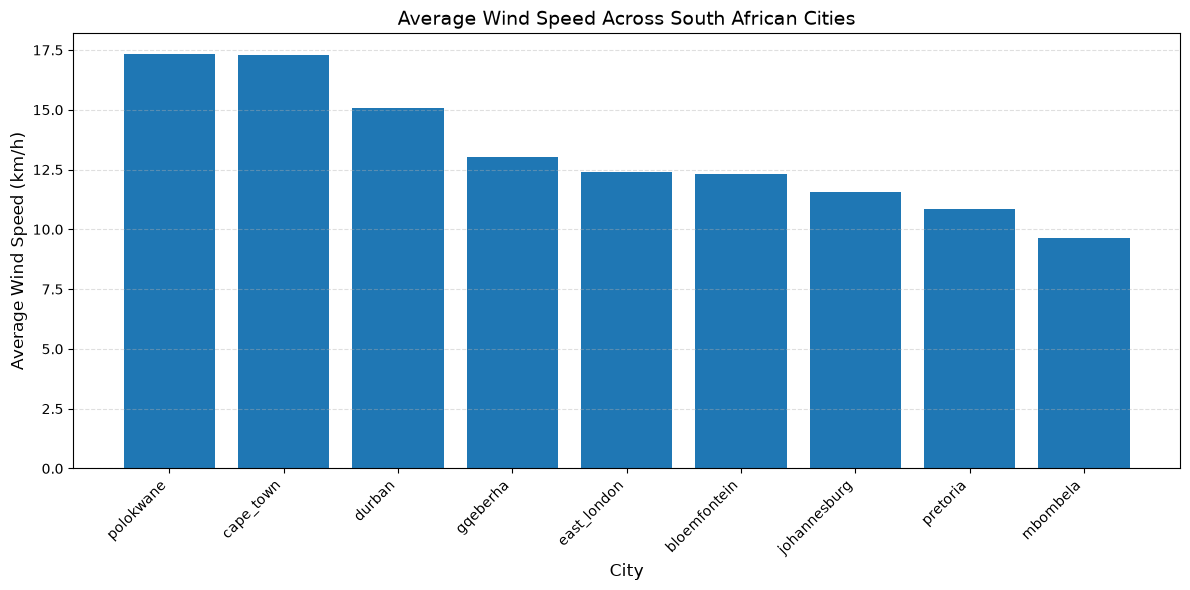

In [8]:
# Compare average wind speed across cities
wind_summary = city_summary.sort_values(
    by="average_wind_speed",
    ascending=False
)

# Create the chart
plt.figure(figsize=(12, 6))

plt.bar(
    wind_summary["city"],
    wind_summary["average_wind_speed"]
)

# Add a title and labels
plt.title("Average Wind Speed Across South African Cities", fontsize=14)
plt.xlabel("City", fontsize=12)
plt.ylabel("Average Wind Speed (km/h)", fontsize=12)

# Improve readability
plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()

# Display the chart
plt.show()

# Conclusion

This project developed a weather data pipeline to collect, transform, validate, and store weather data for nine South African cities.

The processed dataset contains 87 weather records across nine cities. Data quality checks confirmed that there were no missing values, duplicate rows, or duplicate city-timestamp combinations.

The analysis compared average temperature, humidity, and wind speed across the selected cities. Three bar charts were created to visualise differences in recorded weather conditions.

Pretoria recorded the highest average temperature at 27.03°C, while Cape Town recorded the lowest at 16.98°C.

Gqeberha recorded the highest average humidity at 70.60%, while Pretoria recorded the lowest at 28.90%.

Polokwane recorded the highest average wind speed at 17.34 km/h, while Mbombela recorded the lowest at 9.65 km/h.

These findings describe the collected observations rather than long-term climate patterns. Since readings may have been collected at different times, the averages do not necessarily represent weather conditions at the same moment.

The project demonstrates practical skills in Python, pandas, data validation, data pipelines, SQLite, testing, and data visualisation.

In [12]:
print("Rows in dataset:", len(df))
print("Rows counted in city summary:", city_summary["total_records"].sum())

Rows in dataset: 87
Rows counted in city summary: 87


In [13]:
import sqlite3
import pandas as pd
from pathlib import Path

project_dir = Path.home() / "Electives" / "South_african_weather_pipeline"
db_path = project_dir / "database" / "weather.db"

print("Database exists:", db_path.exists())
print("Database path:", db_path)

Database exists: True
Database path: /home/wtc05/Electives/South_african_weather_pipeline/database/weather.db


In [14]:
conn = sqlite3.connect(db_path)

tables = pd.read_sql_query(
    "SELECT name FROM sqlite_master WHERE type='table';",
    conn
)

print("Tables found in the database:")
display(tables)

Tables found in the database:


,name
0,weather


In [15]:
weather_count = pd.read_sql_query(
    "SELECT COUNT(*) AS total_records FROM weather;",
    conn
)

display(weather_count)

,total_records
0,87


In [16]:
columns = pd.read_sql_query(
    "PRAGMA table_info(weather);",
    conn
)

display(columns)

,cid,name,type,notnull,dflt_value,pk
0,0,city,TEXT,1,None,0
1,1,timestamp,TEXT,1,None,0
2,2,temperature_c,REAL,0,None,0
3,3,humidity_percent,REAL,0,None,0
4,4,wind_speed_kmh,REAL,0,None,0


In [17]:
missing_values = pd.read_sql_query(
    """
    SELECT
        SUM(CASE WHEN city IS NULL THEN 1 ELSE 0 END) AS missing_city,
        SUM(CASE WHEN timestamp IS NULL THEN 1 ELSE 0 END) AS missing_timestamp,
        SUM(CASE WHEN temperature_c IS NULL THEN 1 ELSE 0 END) AS missing_temperature,
        SUM(CASE WHEN humidity_percent IS NULL THEN 1 ELSE 0 END) AS missing_humidity,
        SUM(CASE WHEN wind_speed_kmh IS NULL THEN 1 ELSE 0 END) AS missing_wind_speed
    FROM weather;
    """,
    conn
)

display(missing_values)

,missing_city,missing_timestamp,missing_temperature,missing_humidity,missing_wind_speed
0,0,0,0,0,0


In [18]:
duplicates = pd.read_sql_query(
    """
    SELECT
        city,
        timestamp,
        temperature_c,
        humidity_percent,
        wind_speed_kmh,
        COUNT(*) AS occurrences
    FROM weather
    GROUP BY
        city,
        timestamp,
        temperature_c,
        humidity_percent,
        wind_speed_kmh
    HAVING COUNT(*) > 1;
    """,
    conn
)

print("Duplicate groups found:", len(duplicates))
display(duplicates)

Duplicate groups found: 0


,city,timestamp,temperature_c,humidity_percent,wind_speed_kmh,occurrences


In [19]:
cities = pd.read_sql_query(
    """
    SELECT city, COUNT(*) AS total_records
    FROM weather
    GROUP BY city
    ORDER BY city;
    """,
    conn
)

display(cities)
print("Total cities:", len(cities))

,city,total_records
0,bloemfontein,10
1,cape_town,8
2,durban,10
3,east_london,9
4,gqeberha,10
5,johannesburg,10
6,mbombela,10
7,polokwane,10
8,pretoria,10


Total cities: 9
